# Section 1: Exploratory Data Analysis (EDA)
**Author: Eva Petrovska**

Goal: Understand the CIFAR-10 dataset before cleaning and training of models. We examine class balance, pixel statistics, correlations, missing values, outliers, and duplicates.

### Section 1.1 Necessary Libraries, Dataset Loading, & Overview

In [1]:
# ======================================================
# DOWNLOAD HUGGING FACE LIBRARY
# ======================================================

# "datasets" is the Hugging Face library
# It contains many versions of the CIFAR-10 including pretrained models on it
# Tested that it's much faster than original Toronto server
# -q = "quiet" so it doesn't print a wall of text
!pip install -q datasets

In [2]:
# ======================================================
# CORE LIBRARIES & BASIC ADJUSTMENTS
# ======================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import hashlib

# ML LIBRARIES
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# LOAD DATASET
from datasets import load_dataset

# Make all plots look clean and consistent
sns.set_theme(style="whitegrid")

In [3]:
# ======================================================
# LOAD THE DATA
# ======================================================

# Download the CIFAR-10 from Hugging Face
# It already comes split into "train" and "test"
ds = load_dataset("uoft-cs/cifar10")

# Each image is a PIL image object
# Convert to NumPy arrays for computation
# Shape (number_of_images, 32, 32, 3)
# 32x32 = width and height in pixels
# 3 is for RGB

# Get the training and testing data
x_train = np.array([np.array(img) for img in ds["train"]["img"]])
y_train = np.array(ds["train"]["label"])

x_test = np.array([np.array(img) for img in ds["test"]["img"]])
y_test = np.array(ds["test"]["label"])

# The 10 class names
class_names = ds["train"].features["label"].names

print("Classes:", class_names)

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [4]:
# ======================================================
# BASIC INFORMATION
# ======================================================

# Shape and data types
print("Train images:", x_train.shape)
print("Test images: ", x_test.shape)
print("Data type:   ", x_train.dtype)

# Pixel range values (they should be between 0 and 255)
print("Min pixel:", x_train.min())
print("Max pixel:", x_train.max())

# Train/test split confirmation
# CIFAR-10 is pre-split: 50,000 train + 10,000 test
# About 83% 17%, close to the 80% 20% that is asked
total = len(x_train) + len(x_test)
print(f"Train share: {len(x_train) / total:.1%}")

# Check for missing values
# Convert to float because NaN only works on this type
missing_pixels = np.isnan(x_train.astype(float)).sum()
missing_labels = np.isnan(y_train.astype(float)).sum()
print("Missing pixel values: ", missing_pixels)
print("Missing labels:   ", missing_labels)

# Check for invalid labels
# Every label must be one of 0-9
# Empty set means all are valid
invalid = set(np.unique(y_train)) - set(range(10))
print("Invalid labels:", invalid if invalid else "none")

Train images: (50000, 32, 32, 3)
Test images:  (10000, 32, 32, 3)
Data type:    uint8
Min pixel: 0
Max pixel: 255
Train share: 83.3%
Missing pixel values:  0
Missing labels:    0
Invalid labels: none


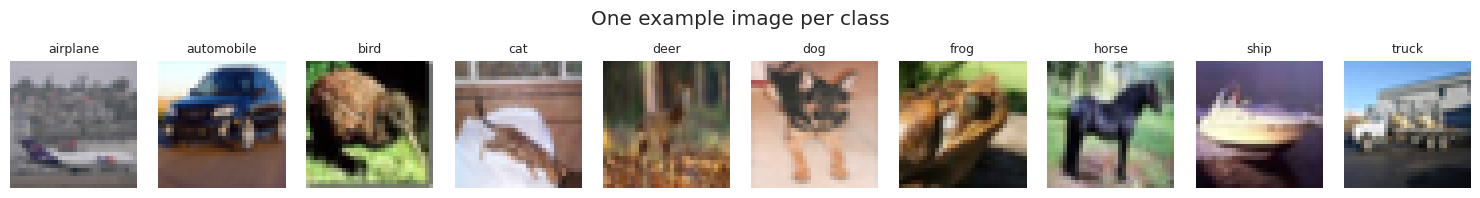

In [5]:
# ======================================================
# EXAMPLE IMAGES
# ======================================================

# Show one example image from every class
fig, axes = plt.subplots(1, 10, figsize=(15, 2))

for c in range(10):
    # Find the first image that belongs to class c
    i = np.where(y_train == c)[0][0]

    axes[c].imshow(x_train[i])
    axes[c].set_title(class_names[c], fontsize=9)
    axes[c].axis("off")  # hide the axis ticks

plt.suptitle("One example image per class")
plt.tight_layout()
plt.show()

### Section 1.2 Descriptive Statistics and Visualizations

            Train  Test
airplane     5000  1000
automobile   5000  1000
bird         5000  1000
cat          5000  1000
deer         5000  1000
dog          5000  1000
frog         5000  1000
horse        5000  1000
ship         5000  1000
truck        5000  1000


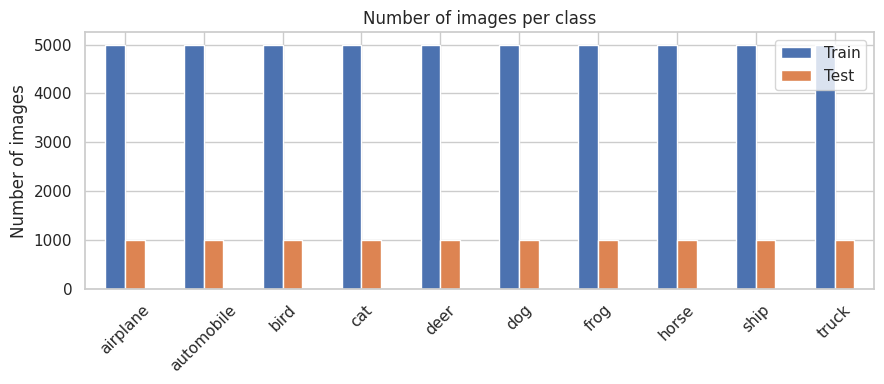

In [6]:
# ======================================================
# VISUALIZATION OF CLASS DISTRIBUTIONS
# ======================================================

# Count number of images per class in train and test
train_counts = pd.Series(y_train).value_counts().sort_index()
test_counts = pd.Series(y_test).value_counts().sort_index()

# Make new table with class names
counts_df = pd.DataFrame({
    "Train": train_counts.values,
    "Test": test_counts.values,
}, index=class_names)

print(counts_df)

# Visualize using bar chart - if all equal, classes are balanced
counts_df.plot(kind="bar", figsize=(9, 4))
plt.title("Number of images per class")
plt.ylabel("Number of images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [7]:
# ======================================================
# DESCRIPTIVE STATISTICS
# ======================================================
# Obtain mean, median, std, min, and max for each color channel (RGB)
# Important for normalization later
channels = ["Red", "Green", "Blue"]
rows = []

# Iterate through each channel
for ch in range(3):
    # Take every pixel value of this channel, as one long list
    vals = x_train[:, :, :, ch].ravel()

    rows.append({
        "Channel": channels[ch],
        "Mean": vals.mean(),
        "Median": np.median(vals),
        "Std": vals.std(),
        "Min": vals.min(),
        "Max": vals.max(),
    })

# Make table
stats_df = pd.DataFrame(rows).set_index("Channel").round(2)
print(stats_df)

           Mean  Median    Std  Min  Max
Channel                                 
Red      125.31   123.0  62.99    0  255
Green    122.95   121.0  62.09    0  255
Blue     113.87   104.0  66.70    0  255


In [8]:
# ======================================================
# FEATURE ENGINEERING
# ======================================================

# Images don't have columns so we create simple stats to describe each one
# Account for amount of red, green, blue, brightness, and contrast
features = pd.DataFrame({
    # Average amount of each colour in the image
    "mean_red": x_train[:, :, :, 0].mean(axis=(1, 2)),
    "mean_green": x_train[:, :, :, 1].mean(axis=(1, 2)),
    "mean_blue": x_train[:, :, :, 2].mean(axis=(1, 2)),
    # Overall brightness = average of all pixels
    "brightness": x_train.mean(axis=(1, 2, 3)),
    # Contrast = how spread out the pixel values are
    "contrast": x_train.std(axis=(1, 2, 3)),
})

# Add the class name to compare classes
features["label"] = [class_names[i] for i in y_train]

# Average of each feature per class
print(features.groupby("label").mean().round(1))

            mean_red  mean_green  mean_blue  brightness  contrast
label                                                            
airplane       134.0       142.9      150.2       142.4      52.1
automobile     120.2       115.9      114.0       116.7      60.5
bird           124.8       125.3      108.1       119.4      46.5
cat            126.3       116.4      106.0       116.2      55.3
deer           120.3       118.6       96.4       111.8      45.6
dog            127.5       118.5      106.2       117.4      55.4
frog           119.9       111.8       88.0       106.6      47.7
horse          128.0       122.4      106.3       118.9      56.4
ship           125.0       134.0      141.4       133.5      55.1
truck          127.2       123.8      121.9       124.3      63.6


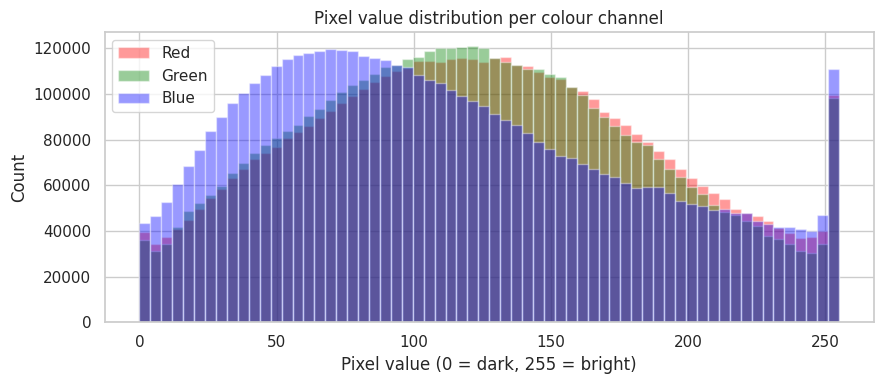

In [9]:
# ======================================================
# PIXEL HISTOGRAM
# ======================================================

# Check how the pixel values are spread out for each color
# Use a sample of 5000 images to make it faster
colors = ["red", "green", "blue"]

plt.figure(figsize=(9, 4))
for ch in range(3):
    vals = x_train[:5000, :, :, ch].ravel()
    plt.hist(vals, bins=64, alpha=0.4,
             color=colors[ch], label=channels[ch])

plt.title("Pixel value distribution per colour channel")
plt.xlabel("Pixel value (0 = dark, 255 = bright)")
plt.ylabel("Count")
plt.legend()
plt.tight_layout()
plt.show()

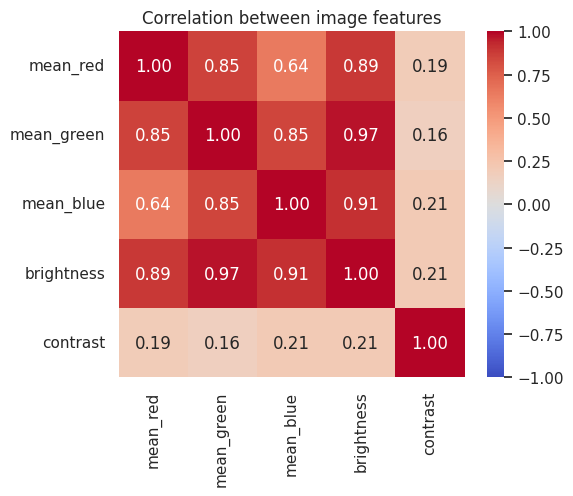

In [10]:
# ======================================================
# CORRELATION HEATMAP
# ======================================================

# Correlation between feature images
# +1 move together, 0 no relationship, -1 opposites
corr = features.drop(columns="label").corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation between image features")
plt.tight_layout()
plt.show()

### Section 1.3 Data Quality and Clustering

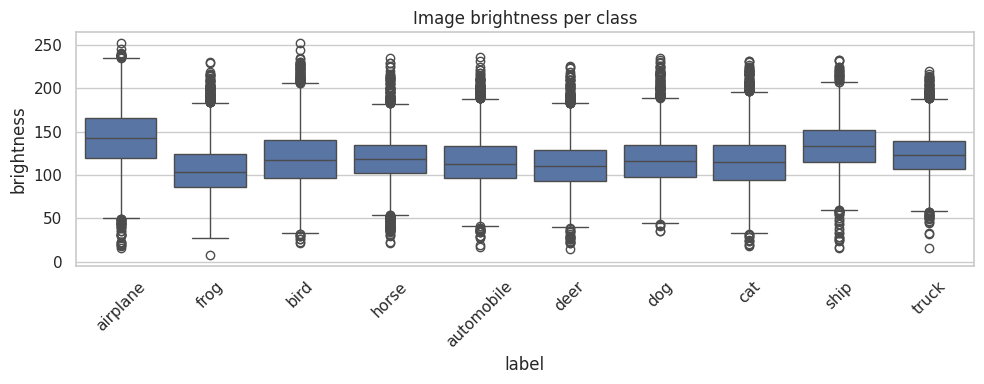

Brightness outliers:  820
Very low-contrast images:  1


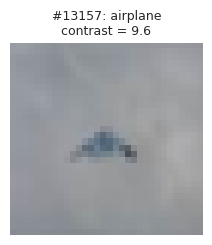

In [11]:
# ======================================================
# BOXPLOT AND OUTLIERS
# ======================================================

# Make a boxplot of brightness per class
plt.figure(figsize=(10, 4))
sns.boxplot(data=features, x="label", y="brightness")
plt.title("Image brightness per class")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Interquartile range (IQR) for outliers
# Anything below Q1 - 1.5*IQR or above Q3 + 1.5*IQR is an outlier

q1 = features["brightness"].quantile(0.25)
q3 = features["brightness"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

bright_outliers = features[
    (features["brightness"] < lower) |
    (features["brightness"] > upper)
]

# Check for very low contrast images
low_contrast = features[features["contrast"]< 10]

print("Brightness outliers: ", len(bright_outliers))
print("Very low-contrast images: ", len(low_contrast))

# Show the low contrast images
for i in low_contrast.index:
    plt.figure(figsize=(2.5, 2.5))
    plt.imshow(x_train[i])
    plt.title(f"#{i}: {class_names[y_train[i]]}\n"
              f"contrast = {features.loc[i, 'contrast']:.1f}",
              fontsize=9)
    plt.axis("off")
    plt.show()

In [12]:
# ======================================================
# DUPLICATE CHECK
# ======================================================

# Turn every image into a hash
# Each one gets a unique value
# Two identical images get the exact same value
train_hashes = [hashlib.md5(img.tobytes()).hexdigest()
                for img in x_train]
test_hashes = [hashlib.md5(img.tobytes()).hexdigest()
               for img in x_test]

# Duplicates = total images - unique hashes
dup_in_train = len(train_hashes) - len(set(train_hashes))
dup_in_test = len(test_hashes) - len(set(test_hashes))

# Check for images that appear in both sets (train and test)
# This is "data leakage"
overlap = len(set(train_hashes) & set(test_hashes))

print("Duplicates inside train:", dup_in_train)
print("Duplicates inside test: ", dup_in_test)
print("Train/test overlap:     ", overlap)

Duplicates inside train: 0
Duplicates inside test:  0
Train/test overlap:      0
